# FerQueue · Alur PCV dan perbandingan bounding box

Pilih kernel **Python (FerQueue PCV)**. Jalankan sel dari atas ke bawah atau pilih **Run All Cells**.

Notebook mengikuti [panduan PCV FerQueue](../../../docs/PCV_MANUAL.md). Lima gambar dari tiap kelas **Mobil**, **Truk**, dan **Bus** disalin dari split test ke `data/processed/pcv-notebook-samples/`. `samples.json` menghubungkan setiap salinan dengan gambar dan kotak anotasi pada manifest.

Alur yang diperagakan adalah **data dan manifest → segmentasi untuk review dan preview citra → artefak training dan export → prediksi → evaluasi kotak**. Notebook memakai hasil konversi, training, dan export yang sudah tersedia.

## 1. Periksa sampel dan manifest · `inspect` → `prepare`

Di PCV, label YOLO dipisahkan lewat `stage-yolo`, dikonversi ke COCO dengan converter Taeyoung96, lalu dihubungkan ke gambar raw lewat `adopt-coco`. `prepare` membekukan kelas, split, dan kotak anotasi. Sel ini membaca manifest yang dipakai saat training dan mencocokkan isi salinan dengan hash gambar test.

In [1]:
from collections import Counter
from hashlib import sha256
import json
from pathlib import Path
import sys

from PIL import Image

ROOT_OVERRIDE = None  # Contoh: Path("/home/foxxyy/project/ferqueue")
CONFIG_PATH = "apps/computer-vision/configs/coco.json"
SAMPLE_DIR = "data/processed/pcv-notebook-samples"

cwd = Path.cwd()
root = Path(ROOT_OVERRIDE).expanduser().resolve() if ROOT_OVERRIDE else next(
    (folder for folder in (cwd, *cwd.parents) if (folder / "pcv.py").is_file()),
    None,
)
if root is None or not (root / "pcv.py").is_file():
    raise FileNotFoundError("Isi ROOT_OVERRIDE dengan path folder yang berisi pcv.py.")

src = str(root / "apps/computer-vision/src")
if src not in sys.path:
    sys.path.insert(0, src)

from ferqueue_cv.settings import load_config

sample_dir = root / SAMPLE_DIR
index = json.loads((sample_dir / "samples.json").read_text(encoding="utf-8"))
config = load_config(CONFIG_PATH, root)
config["run_dir"] = index["run_dir"]
run_dir = root / config["run_dir"]
frozen = json.loads((run_dir / "inputs.json").read_text(encoding="utf-8"))
metadata = json.loads((run_dir / "export.json").read_text(encoding="utf-8"))
manifest = frozen["manifest"]
classes = manifest["classes"]
if index["split"] != "test" or metadata["classes"] != classes:
    raise ValueError("Gunakan split test dan urutan kelas yang sama dengan model.")

test_rows = {row["image"]: row for row in manifest["splits"]["test"]}
samples = []
for entry in index["images"]:
    row = test_rows[entry["source"]]
    copy = sample_dir / entry["file"]
    if sha256(copy.read_bytes()).hexdigest() != row["sha256"]:
        raise ValueError(f"Isi salinan berbeda dari gambar test: {copy}")
    with Image.open(copy) as source:
        raw = source.convert("RGB")
    class_name = copy.parent.name
    if [classes[box["class_id"] - 1] for box in row["boxes"]] != [class_name]:
        raise ValueError(f"Anotasi sampel tidak cocok dengan folder kelas: {copy}")
    samples.append({"file": entry["file"], "class_name": class_name, "row": row, "raw": raw})

counts = Counter(sample["class_name"] for sample in samples)
print(f'{len(samples)} salinan dari {len(test_rows)} gambar test · seed {index["seed"]}')
for name in classes:
    print(f"{name}: {counts[name]} gambar")

15 salinan dari 293 gambar test · seed 42
Mobil: 5 gambar
Truk: 5 gambar
Bus: 5 gambar


## 2. Review mask dan preprocessing · `segment` / `preview`

Seperti perintah `pcv.py segment`, GrabCut pada tahap **review** dimulai dari kotak **anotasi**. Contoh di bawah memakai satu gambar tiap kelas. Mask menunjukkan perkiraan foreground dan perlu diperiksa secara visual.

PCV mengolah citra dalam urutan **RGB → Gaussian denoise → CLAHE → gamma**. Tiga panel tengah menunjukkan contoh jika opsi tersebut diaktifkan. Panel terakhir memakai pengaturan preprocessing dari `export.json`. Gambar pada panel terakhir inilah yang masuk ke SSD pada kedua percobaan.

In [2]:
from PIL import ImageDraw
import matplotlib.pyplot as plt

from ferqueue_cv.processing import grabcut_mask, preprocess_image

preprocessing = metadata.get("preprocessing", {})
print("Preprocessing model", preprocessing)
print("GrabCut", config["segmentation"])

for sample in samples:
    sample["processed"] = preprocess_image(sample["raw"], preprocessing)

for name in classes:
    sample = next(sample for sample in samples if sample["class_name"] == name)
    raw = sample["raw"]
    processed = sample["processed"]
    box = sample["row"]["boxes"][0]

    annotated = processed.copy()
    ImageDraw.Draw(annotated).rectangle(
        (box["xmin"] * raw.width, box["ymin"] * raw.height,
         box["xmax"] * raw.width, box["ymax"] * raw.height),
        outline="gold", width=3,
    )
    mask, status = grabcut_mask(processed, box, config["segmentation"])
    fig, axes = plt.subplots(1, 2, figsize=(7, 3), layout="constrained")
    fig.suptitle(f'Review segmentasi · {sample["file"]}')
    axes[0].imshow(annotated)
    axes[0].set_title("Kotak anotasi")
    if mask is not None:
        axes[1].imshow(mask, cmap="gray", vmin=0, vmax=255)
    axes[1].set_title("Mask dari anotasi" if mask is not None else status)
    for ax in axes:
        ax.axis("off")
    plt.show()

    denoised = preprocess_image(raw, {"denoise_kernel": 3})
    enhanced = preprocess_image(denoised, {"clahe_clip_limit": 2.0})
    adjusted = preprocess_image(enhanced, {"gamma": 0.9})
    fig, axes = plt.subplots(1, 5, figsize=(13, 3), layout="constrained")
    fig.suptitle(f'Preview citra · {sample["file"]}')
    for ax, image, title in zip(
        axes,
        (raw, denoised, enhanced, adjusted, processed),
        ("Asli", "Gaussian 3×3", "+ CLAHE 2.0", "+ Gamma 0.9", "Input model"),
    ):
        ax.imshow(image)
        ax.set_title(title)
        ax.axis("off")
    plt.show()

Preprocessing model {'clahe_clip_limit': 0, 'clahe_grid_size': 8, 'denoise_kernel': 0, 'gamma': 1.0}
GrabCut {'iterations': 5, 'morphology_kernel': 3}


<Figure size 700x300 with 2 Axes>

<Figure size 1300x300 with 5 Axes>

<Figure size 700x300 with 2 Axes>

<Figure size 1300x300 with 5 Axes>

<Figure size 700x300 with 2 Axes>

<Figure size 1300x300 with 5 Axes>

## 3. Periksa artefak model · `plan` → `build-records` → `train` → `export`

PCV membuat TFRecord dari manifest dan melatih SSD MobileNet V2 FPNLite 320×320. Export mengemas checkpoint menjadi TensorFlow SavedModel. Sel ini membaca rencana training yang dibekukan dan memuat model yang sudah diekspor.

In [3]:
from ferqueue_cv.settings import training_plan
from ferqueue_cv.training import load_detector

plan = training_plan(frozen["config"], manifest)
print(f'{plan["train_images"]} gambar train · batch {plan["batch_size"]} · {plan["num_steps"]} langkah direncanakan')
detector, _, metadata = load_detector(config, root)
print(f'{metadata["model"]} · {metadata["checkpoint"]}')
print(metadata["saved_model"])

683 gambar train · batch 2 · 3420 langkah direncanakan


2026-11-12 13:57:47.427975: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-11-12 13:57:47.449869: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-11-12 13:57:47.449925: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-11-12 13:57:47.451106: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-11-12 13:57:47.456803: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-11-12 13:57:47.457626: I tensorflow/core/platform/cpu_feature_guard.cc:1

ssd_mobilenet_v2_fpnlite_320x320_coco17_tpu-8 · ckpt-36
models/mobilenet/runs/pcv-cpu-full-001/exports/ckpt-36/saved_model


## 4. Prediksi SSD · `predict`

Jalankan deteksi pada 15 salinan gambar. SSD memprediksi kelas, confidence, dan kotak. Filter confidence dan NMS memakai config PCV. NMS menekan kotak yang tumpang tindih. Untuk gambar hasil, koordinat kotak dikonversi ke piksel dengan urutan `xmin, ymin, xmax, ymax`.

In [4]:
from time import perf_counter

import numpy as np
from PIL import ImageChops

from ferqueue_cv.postprocessing import select_detections
from ferqueue_cv.training import detect



def baseline_boxes(image):
    result = detect(detector, image)
    width, height = image.size
    boxes = []
    for index in select_detections(result, config):
        class_id = int(result["detection_classes"][index])
        ymin, xmin, ymax, xmax = np.clip(result["detection_boxes"][index], 0, 1)
        if 1 <= class_id <= len(classes) and xmin < xmax and ymin < ymax:
            boxes.append({
                "class_id": class_id,
                "score": float(result["detection_scores"][index]),
                "xyxy": [xmin * width, ymin * height, xmax * width, ymax * height],
            })
    return boxes


for sample in samples:
    sample["baseline"] = baseline_boxes(sample["processed"])

print(f'Confidence ≥ {config["confidence_threshold"]} · IoU NMS {config.get("nms_iou_threshold", 0.45)}')
for name in classes:
    group = [sample for sample in samples if sample["class_name"] == name]
    detected = sum(bool(sample["baseline"]) for sample in group)
    print(f"{name}: {detected}/{len(group)} gambar dengan prediksi")

Confidence ≥ 0.5 · IoU NMS 0.45
Mobil: 5/5 gambar dengan prediksi
Truk: 5/5 gambar dengan prediksi
Bus: 5/5 gambar dengan prediksi


## 5. Bandingkan kotak asli dengan kotak dari mask

Untuk eksperimen ini, GrabCut dimulai dari kotak **prediksi SSD** pada langkah 4. Kotak kedua mengikuti batas luar mask. Kelas dan confidence sama pada kedua hasil. Jika mask gagal dibuat atau kosong, hasil kedua memakai kotak awal.

Setiap baris menunjukkan satu sampel. Garis putus-putus **kuning** adalah anotasi test dan garis **hijau** adalah prediksi. Panel mask di tahap ini berasal dari kotak prediksi.

In [5]:
def refine_boxes(image, boxes):
    width, height = image.size
    refined = []
    masks = []
    failures = Counter()
    for box in boxes:
        xmin, ymin, xmax, ymax = box["xyxy"]
        seed_box = {
            "xmin": xmin / width, "ymin": ymin / height,
            "xmax": xmax / width, "ymax": ymax / height,
        }
        mask, status = grabcut_mask(image, seed_box, config.get("segmentation"))
        if mask is None:
            failures[status] += 1
            refined.append(box)
        else:
            refined.append({**box, "xyxy": mask.getbbox()})
            masks.append(mask)
    return refined, masks, failures


fallbacks = Counter()
segmentation_ms = []
for sample in samples:
    image = sample["processed"]
    started = perf_counter()
    segmented, masks, failures = refine_boxes(image, sample["baseline"])
    segmentation_ms.append((perf_counter() - started) * 1000)
    fallbacks.update(failures)

    mask_preview = Image.new("L", image.size)
    for mask in masks:
        mask_preview = ImageChops.lighter(mask_preview, mask)
    sample["segmented"] = segmented
    sample["mask"] = mask_preview
    sample["references"] = [
        {"class_id": box["class_id"],
         "xyxy": [box["xmin"] * image.width, box["ymin"] * image.height,
                  box["xmax"] * image.width, box["ymax"] * image.height]}
        for box in sample["row"]["boxes"]
    ]
    print(f'{sample["file"]} · {len(masks)}/{len(sample["baseline"])} mask terbentuk')

Mobil/01.jpg · 1/1 mask terbentuk
Mobil/02.jpg · 1/1 mask terbentuk
Mobil/03.jpg · 1/1 mask terbentuk
Mobil/04.jpg · 1/1 mask terbentuk
Mobil/05.jpg · 1/1 mask terbentuk
Truk/01.jpg · 1/1 mask terbentuk
Truk/02.jpg · 1/1 mask terbentuk
Truk/03.jpg · 1/1 mask terbentuk
Truk/04.jpg · 1/1 mask terbentuk
Truk/05.jpg · 1/1 mask terbentuk
Bus/01.jpg · 1/1 mask terbentuk
Bus/02.jpg · 1/1 mask terbentuk
Bus/03.jpg · 1/1 mask terbentuk
Bus/04.jpg · 1/1 mask terbentuk
Bus/05.jpg · 1/1 mask terbentuk


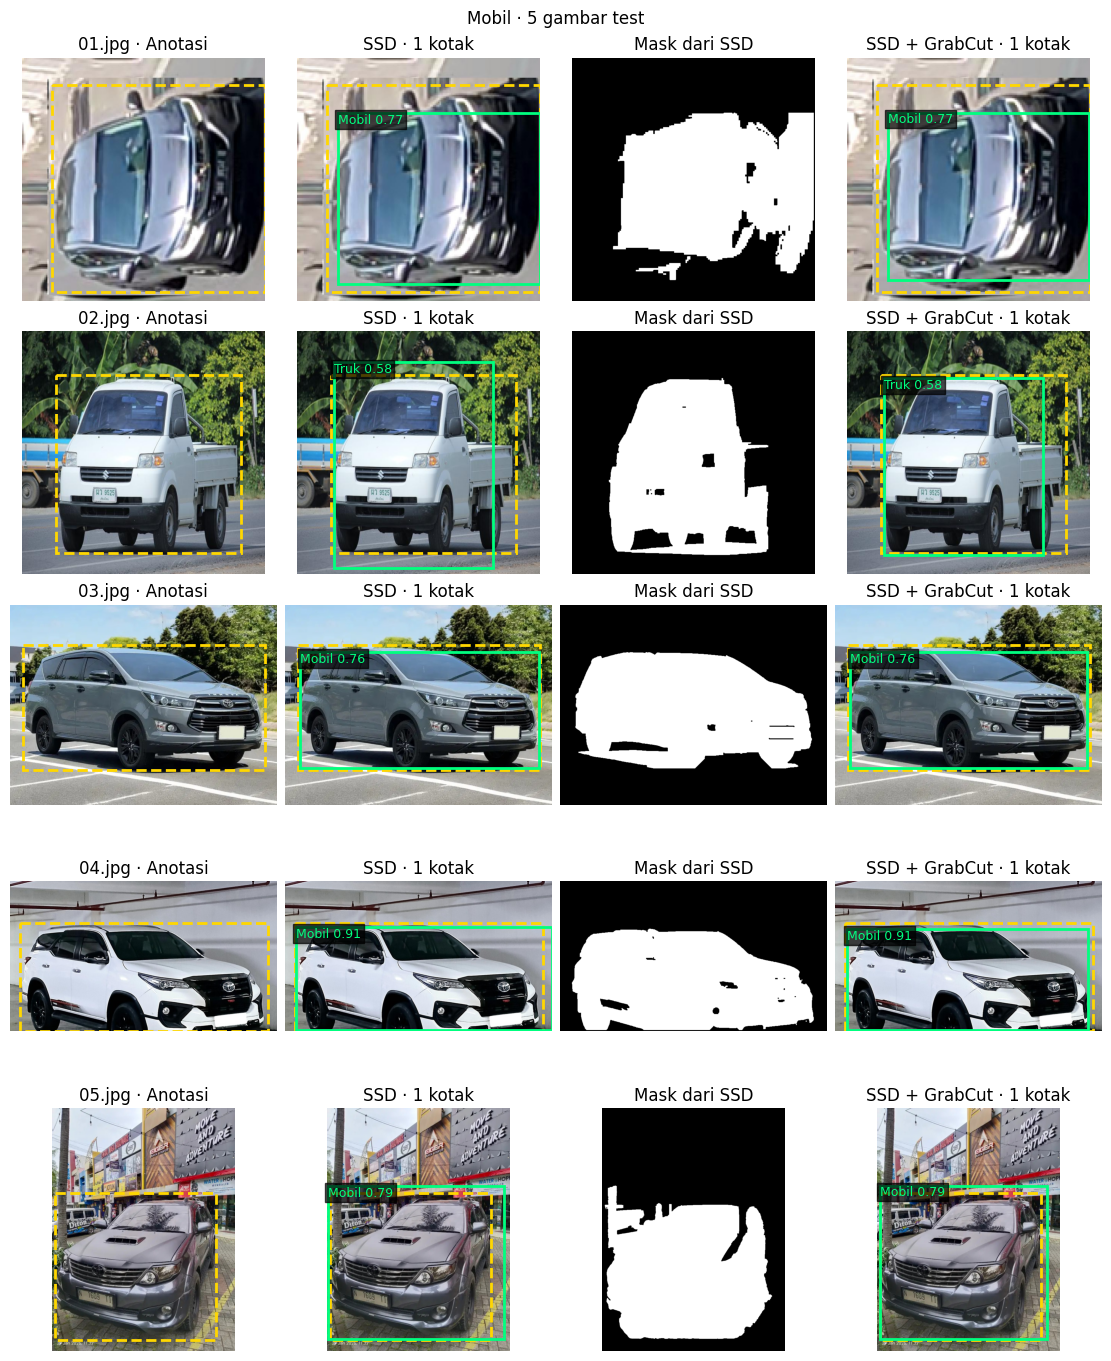

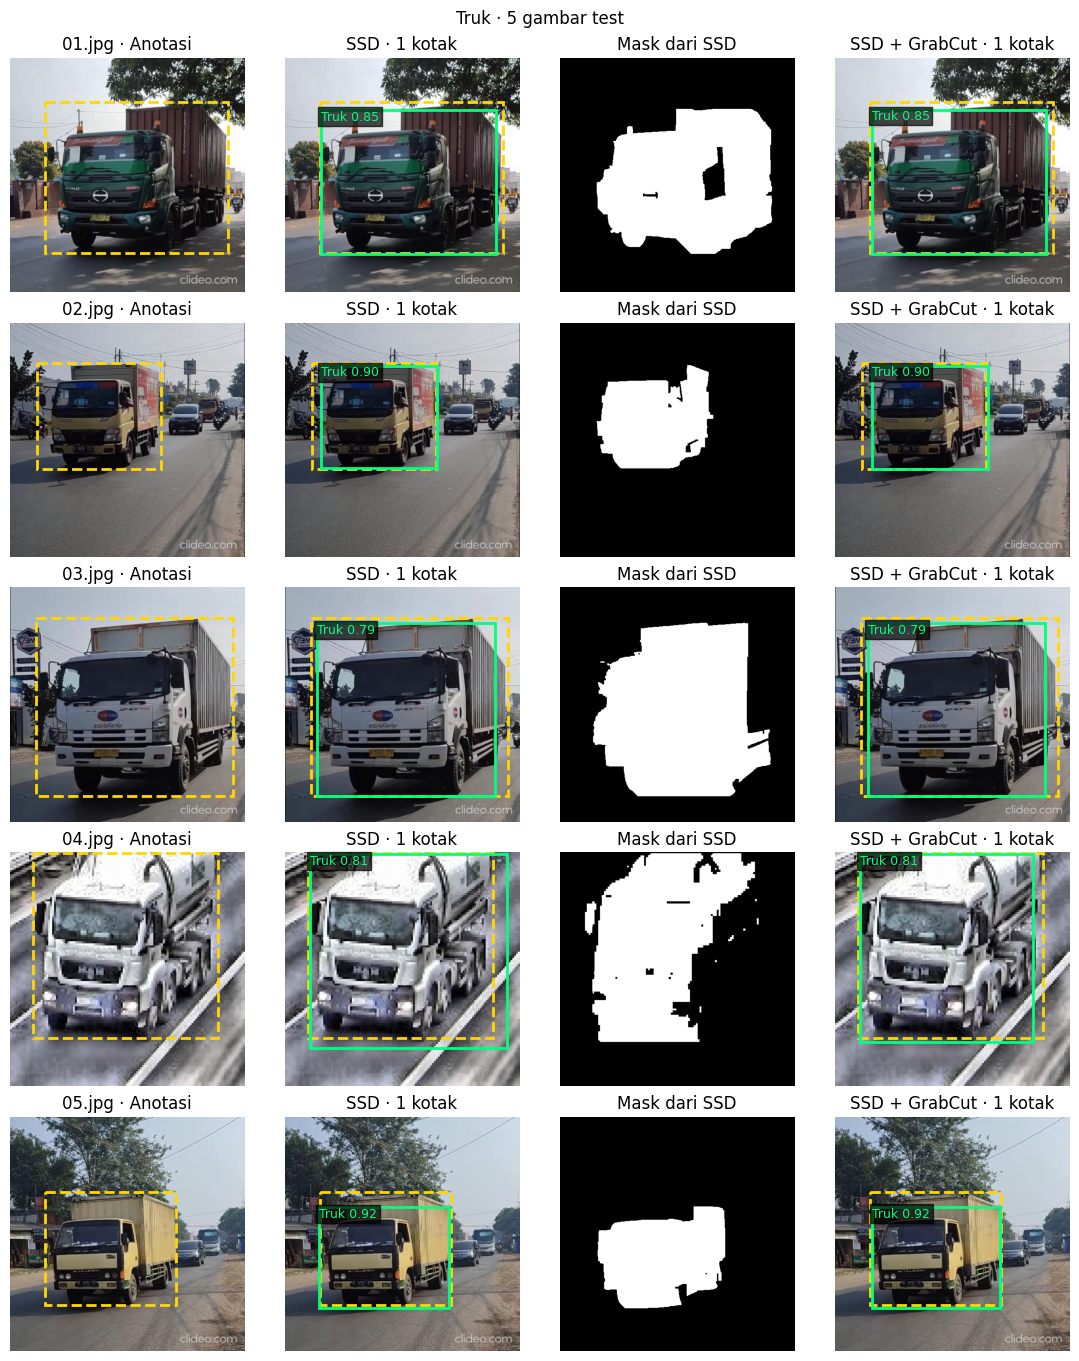

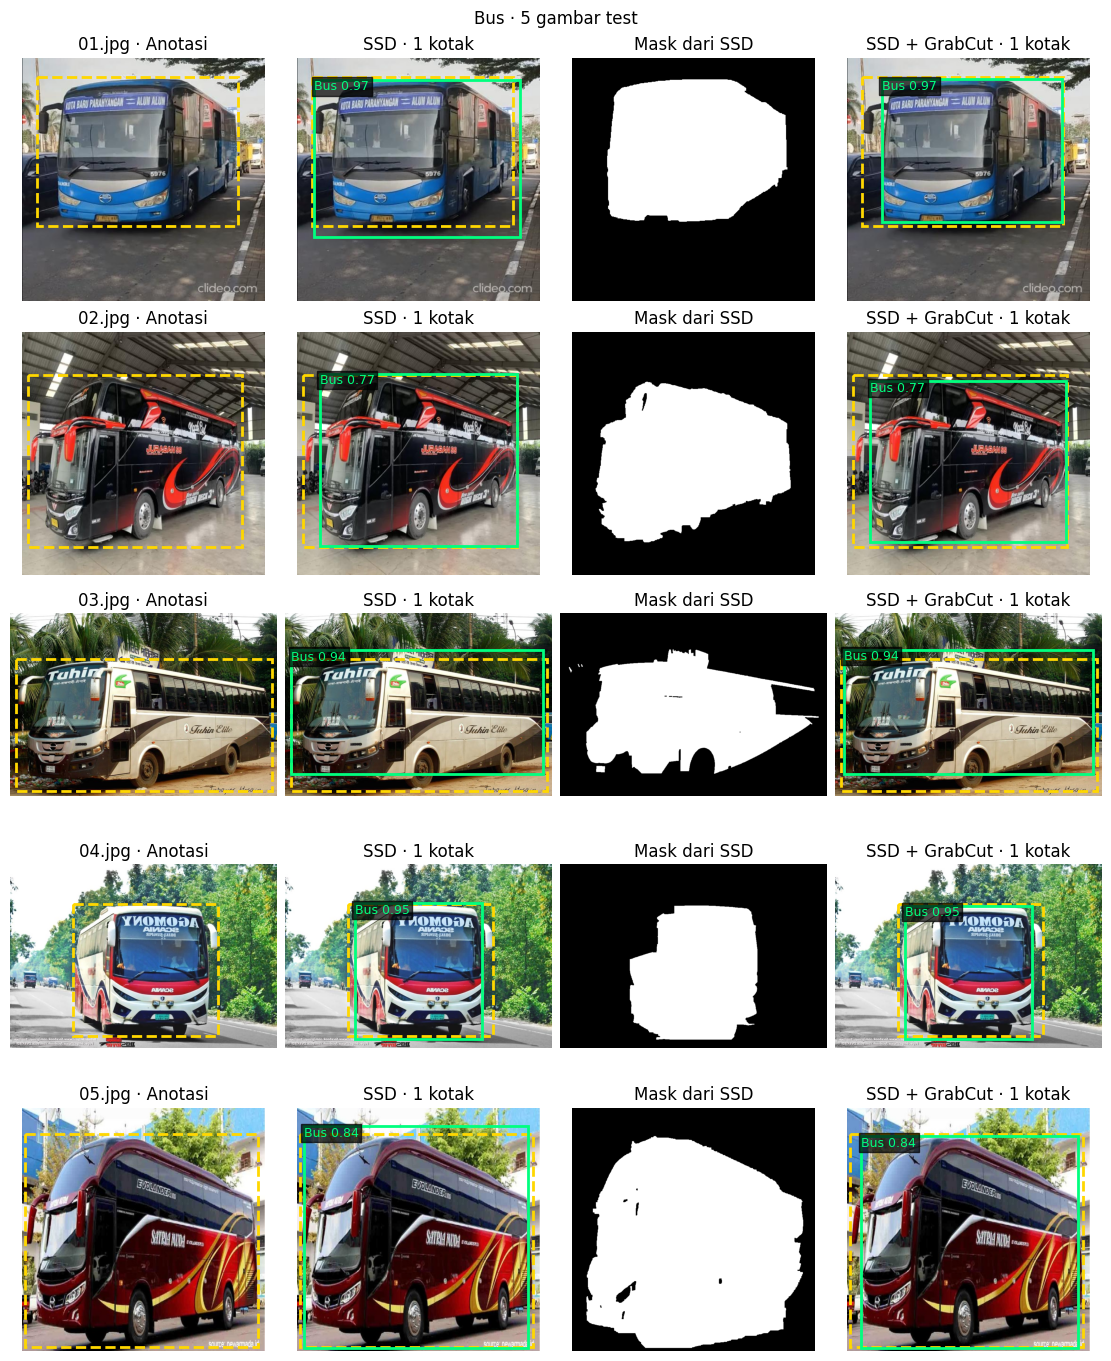

In [6]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle


def draw_boxes(ax, boxes, *, color, linestyle="-"):
    for box in boxes:
        xmin, ymin, xmax, ymax = box["xyxy"]
        ax.add_patch(Rectangle(
            (xmin, ymin), xmax - xmin, ymax - ymin,
            fill=False, edgecolor=color, linestyle=linestyle, linewidth=2,
        ))
        if "score" in box:
            name = classes[box["class_id"] - 1]
            ax.text(
                xmin, ymin, f'{name} {box["score"]:.2f}',
                color=color, fontsize=9, va="top",
                bbox={"facecolor": "black", "alpha": 0.7, "pad": 2},
            )


for name in classes:
    group = [sample for sample in samples if sample["class_name"] == name]
    fig, axes = plt.subplots(
        len(group), 4, figsize=(11, 2.7 * len(group)), squeeze=False, layout="constrained",
    )
    fig.suptitle(f"{name} · {len(group)} gambar test")
    for sample, (original, baseline, mask_ax, segmented) in zip(group, axes):
        image = sample["processed"]
        extent = (0, image.width, image.height, 0)
        original.imshow(sample["raw"], extent=extent)
        original.set_title(Path(sample["file"]).name + " · Anotasi")
        draw_boxes(original, sample["references"], color="gold", linestyle="--")
        for ax, key, title in (
            (baseline, "baseline", "SSD"),
            (segmented, "segmented", "SSD + GrabCut"),
        ):
            ax.imshow(image, extent=extent)
            draw_boxes(ax, sample["references"], color="gold", linestyle="--")
            draw_boxes(ax, sample[key], color="springgreen")
            ax.set_title(f"{title} · {len(sample[key])} kotak")
        mask_ax.imshow(sample["mask"], cmap="gray", vmin=0, vmax=255)
        mask_ax.set_title("Mask dari SSD")
    for ax in axes.flat:
        ax.axis("off")
    plt.show()

## 6. Evaluasi terhadap anotasi test · metrik COCO

**IoU** adalah tumpang tindih kotak prediksi dengan anotasi, dari 0 sampai 1. **AP50** menerima IoU ≥ 0,50. **AP75** menuntut kecocokan yang lebih ketat. **mAP 50–95** merangkum beberapa ambang IoU.

Tabel memakai fungsi metrik COCO FerQueue pada **15 sampel setelah filter tampilan**. Perintah `pcv.py evaluate` memakai seluruh deteksi SavedModel pada split test. Selisih positif di tabel berarti hasil GrabCut lebih baik pada sampel ini.

In [7]:
from contextlib import redirect_stdout
from io import StringIO
from statistics import median

from ferqueue_cv.coco_metrics import compute_coco_metrics


def coco_bbox(box):
    xmin, ymin, xmax, ymax = map(float, box["xyxy"])
    return [xmin, ymin, xmax - xmin, ymax - ymin]


groundtruth = {
    "images": [],
    "annotations": [],
    "categories": [{"id": i, "name": name} for i, name in enumerate(classes, 1)],
}
predictions = {"baseline": [], "segmented": []}
for image_id, sample in enumerate(samples, 1):
    width, height = sample["processed"].size
    groundtruth["images"].append({
        "id": image_id, "file_name": sample["file"], "width": width, "height": height,
    })
    for box in sample["references"]:
        bbox = coco_bbox(box)
        groundtruth["annotations"].append({
            "id": len(groundtruth["annotations"]) + 1, "image_id": image_id,
            "category_id": box["class_id"], "bbox": bbox, "area": bbox[2] * bbox[3], "iscrowd": 0,
        })
    for mode, entries in predictions.items():
        entries.extend({
            "image_id": image_id, "category_id": box["class_id"],
            "bbox": coco_bbox(box), "score": box["score"],
        } for box in sample[mode])

with redirect_stdout(StringIO()):
    metrics = {mode: compute_coco_metrics(groundtruth, boxes) for mode, boxes in predictions.items()}

metric_rows = [
    ("AP50", "Precision/mAP@.50IOU"),
    ("AP75", "Precision/mAP@.75IOU"),
    ("mAP 50–95", "Precision/mAP"),
]
metric_rows.extend((f"mAP {name}", f"PerformanceByCategory/mAP/{name}") for name in classes)
print(f'{"Metrik":<15} {"SSD":>8} {"SSD + GrabCut":>15} {"Selisih":>9}')
for label, suffix in metric_rows:
    key = "DetectionBoxes_" + suffix
    before = metrics["baseline"][key]
    after = metrics["segmented"][key]
    print(f"{label:<15} {before:>8.3f} {after:>15.3f} {after - before:>+9.3f}")

print(f"\nTambahan waktu GrabCut per gambar (median): {median(segmentation_ms):.1f} ms")
print("Kotak awal dipertahankan karena mask gagal:", fallbacks.total())

Metrik               SSD   SSD + GrabCut   Selisih
AP50               0.934           0.934    +0.000
AP75               0.934           0.934    +0.000
mAP 50–95          0.718           0.727    +0.009
mAP Mobil          0.623           0.648    +0.025
mAP Truk           0.771           0.784    +0.013
mAP Bus            0.761           0.750    -0.011

Tambahan waktu GrabCut per gambar (median): 1709.6 ms
Kotak awal dipertahankan karena mask gagal: 0
